In [1]:
import torch
import matplotlib.pyplot as plt

from ngo.numericalanalysis.basisfunctions import *
from ngo.numericalanalysis.linalg import *

In [2]:
class GRF:
    def __init__(self, N_samples, l, n, device, dtype):
        super().__init__()
        self.device = device
        self.dtype = dtype
        self.N_samples = N_samples #Number of GRF samples
        self.l = torch.tensor(l, device=self.device, dtype=dtype) #Length scale of GRF
        self.d = l.shape[-1] #Dimensionality of GRF
        self.n = n  #Number of points in each dimension
        if n==None:
            self.l_Dx_ratio = 1
            self.n = tuple((self.l_Dx_ratio*(1.0 / self.l).ceil().long() + 1).tolist())
        self.mus = self.get_mus()
        self.f_m = self.compute_coeffs()
    
    def get_mus(self):
        mus = ()
        for i in range(self.d):
            mus += (torch.linspace(0,1, self.n[i], device=self.device, dtype=self.dtype),)
        return mus
    
    def compute_covariances(self):
        K_i = ()
        for i in range(self.d):
            mus_i = self.mus[i]
            l_i = self.l[:,i]
            scaled_mus = mus_i[None, :] / l_i[:, None]
            diff = scaled_mus[:,:, None] - scaled_mus[:,None, :]
            dist_sq = diff**2
            K_i += (torch.exp(-0.5 * dist_sq),)
            print(K_i[i].shape)
        return K_i
    
    def compute_coeffs(self):
        K_i = self.compute_covariances()
        L_i = tuple(torch.linalg.cholesky(K) for K in K_i)
        # Sample standard normal variables
        Z = torch.randn(size=(self.N_samples,*self.n), device=self.device, dtype=self.dtype)
        # GRF generation
        self.f = kron_matvec(L_i, Z)
        # Forward solve
        L_i_T = tuple(L.transpose(-2, -1) for L in L_i)
        y = kron_solve_triangular(L_i_T, self.f, upper=True, left=False)
        #Backward solve
        f_m = kron_solve_triangular(L_i, y, upper=False, left=False)
        return f_m

In [3]:
torch.cuda.empty_cache()
l_min = 0.5
l_max = 1
lambdas = torch.rand(100,3)*(l_max - l_min) + l_min
grf = GRF(N_samples=100, l=lambdas, n=(2,3,4), device='cuda', dtype=torch.float64)

/tmp/ipykernel_342372/257917577.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.l = torch.tensor(l, device=self.device, dtype=dtype) #Length scale of GRF


torch.Size([100, 2, 2])
torch.Size([100, 3, 3])
torch.Size([100, 4, 4])
torch.Size([100, 2, 3, 4])


RuntimeError: linalg.solve_triangular: A must be batches of square matrices, but they are 2 by 100 matrices

In [ ]:
grf.f_m.shape

torch.Size([100, 2, 3, 4])

In [ ]:
grf.mus[0].shape

torch.Size([2])

In [ ]:
basis_t = GaussianRBFBasis(lambdas=lambdas[:,0], mus=grf.mus[0])

In [ ]:
t = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
basis_t.forward(t)

RuntimeError: The size of tensor a (2) must match the size of tensor b (100) at non-singleton dimension 0

In [ ]:
t = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
y = torch.sum(grf.f_m[0,:,None]*basis_t.forward(t), dim=0)
plt.plot(t.cpu(), y.cpu())
plt.scatter(grf.mus[0].cpu(), grf.f.cpu(), color='red')

RuntimeError: The size of tensor a (2) must match the size of tensor b (100) at non-singleton dimension 0

In [ ]:
torch.cuda.empty_cache()
lambdas = (0.1,0.1)
grf = GRF(N_samples=1, l=lambdas, n=None, device='cuda', dtype=torch.float64)

AttributeError: 'tuple' object has no attribute 'shape'

In [ ]:
grf.f_m.shape

torch.Size([1, 11, 11])

In [ ]:
basis_t = GaussianRBFBasis(lambdas=grf.l[None,0], mus=grf.mus[0])
basis_x = GaussianRBFBasis(lambdas=grf.l[None,1], mus=grf.mus[1])

basis = TensorProductBasis((basis_t, basis_x))

In [ ]:
x = torch.linspace(0,1,1000, device='cuda', dtype=torch.float64)
X = (t,x)

In [ ]:
basis.forward(grf.f_m, X).shape

torch.Size([1, 1000, 1000])

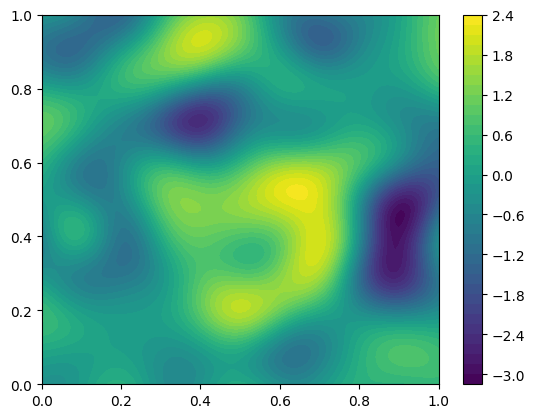

In [ ]:
grid = torch.meshgrid(t.cpu(), x.cpu(), indexing='ij')
mus_grid = torch.meshgrid(grf.mus[0], grf.mus[1], indexing='ij')
plt.contourf(grid[1], grid[0], basis.forward(grf.f_m, X).cpu()[0], levels=50)
plt.colorbar()

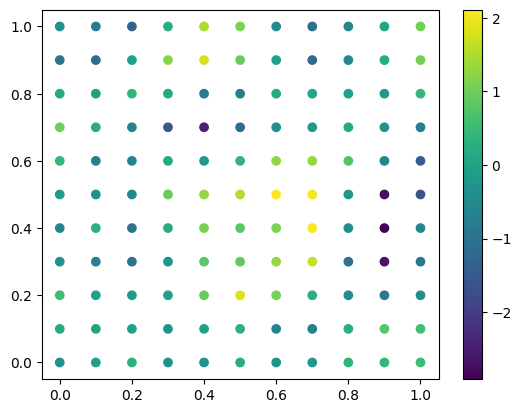

In [ ]:
grid = torch.meshgrid(t.cpu(), x.cpu(), indexing='ij')
mus_grid = torch.meshgrid(grf.mus[0], grf.mus[1], indexing='ij')
plt.scatter(mus_grid[1].cpu(), mus_grid[0].cpu(), c=grf.f[0].cpu())
plt.colorbar()

In [ ]:
l_min = 0.5
l_max = 1
lambdas = torch.rand(100) * (l_max - l_min) + l_min